# 23 — How Many Units Does an Attribution Claim Need?

Three notebooks have reached the same constraint from different directions and
none of them put a number on it.

- **Notebook 14** priced attribution at *"about six real units"* from a learning
  curve — four of the majority class and two of the minority.
- **Notebook 17** found only **6 of 11** units individually clearing the RUL
  floor's safety target, and said a floor is a per-unit promise.
- **Notebook 22** found a label-permutation null whose 95th percentile reaches
  **69–74 %** on eleven units, so any bearing-held-out accuracy below roughly
  72 % is inside what chance achieves.

Each of those is a symptom of the same thing: **eleven units is a small study,
and nobody has measured how small.** This notebook measures it directly.

For each unit count *n*, draw subsets of *n* bearings and, inside each subset,
compute both the accuracy under the **true** labels and the **null band** from
permuting labels within that same subset — the identical bearing-held-out
protocol, just restricted to *n* units. Where the true curve pulls clear of its
own null is the minimum viable study size; the width of the band at each *n* is
the smallest effect that study size could ever resolve.

The measurement runs on Paderborn, which notebook 22 showed carries **both** a
genuinely real effect and a genuinely absent one on the same eleven units — the
geometry channel at p = 0.0043 and the load-zone channel at p = 0.147. That gives
the curve a positive and a negative control built in, which is the only way to
tell a power floor from a broken measurement.

The answer is **about eight units**, and notebook 14's estimate of six was
optimistic. Nulls are cached by `src/build_power_curve.py` (~9 min).

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
D = pd.read_csv(OUT / "power_curve.csv")           # src/build_power_curve.py

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"            # geometry / load-zone throughout
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
CH = {"geometry": C_BLUE, "load-zone": C_ORANGE}

S = (D.groupby(["channel", "n"])
       .agg(true=("true", "mean"), null95=("null_95", "mean"),
            nullmean=("null_mean", "mean"), p=("p", "median"),
            hits=("p", lambda s: int((s < 0.05).sum())), k=("p", "size"))
       .reset_index())
S["margin"] = S["true"] - S["null95"]
S["power"] = S["hits"] / S["k"]
print(S.to_string(index=False, formatters={c: "{:.1%}".format for c in
                                           ("true", "null95", "nullmean", "margin",
                                            "power")}))

  channel  n  true null95 nullmean        p  hits  k margin  power
 geometry  4 79.1%  77.2%    46.5% 0.333333     0 29   2.0%   0.0%
 geometry  5 71.0%  71.1%    41.3% 0.200000     0 29  -0.1%   0.0%
 geometry  6 73.3%  69.2%    42.7% 0.133333     0 30   4.1%   0.0%
 geometry  7 77.9%  72.7%    44.7% 0.057143    12 30   5.2%  40.0%
 geometry  8 82.0%  71.1%    42.6% 0.048780    21 30  10.9%  70.0%
 geometry  9 83.8%  70.5%    44.0% 0.024390    28 30  13.3%  93.3%
 geometry 10 85.3%  70.9%    43.7% 0.024390    11 11  14.4% 100.0%
 geometry 11 85.0%  64.7%    41.8% 0.024390     1  1  20.3% 100.0%
load-zone  4 69.2%  73.4%    47.7% 0.500000     0 29  -4.2%   0.0%
load-zone  5 55.6%  74.2%    43.1% 0.400000     0 29 -18.6%   0.0%
load-zone  6 54.7%  76.2%    43.3% 0.400000     0 30 -21.6%   0.0%
load-zone  7 57.8%  74.2%    45.6% 0.309524     1 30 -16.4%   3.3%
load-zone  8 57.4%  74.5%    42.8% 0.317073     2 30 -17.1%   6.7%
load-zone  9 58.9%  73.3%    44.2% 0.268293     2 30 -14.4%   

## The curve

The left panel is the measurement: the true-label accuracy against the 95th
percentile of that subset's own permuted-label null, as units are added. The two
meet where a claim becomes possible. The right panel is the same thing expressed
as the fraction of subsets in which the effect is actually detected at p < 0.05 —
the statistical power of the protocol at that study size.

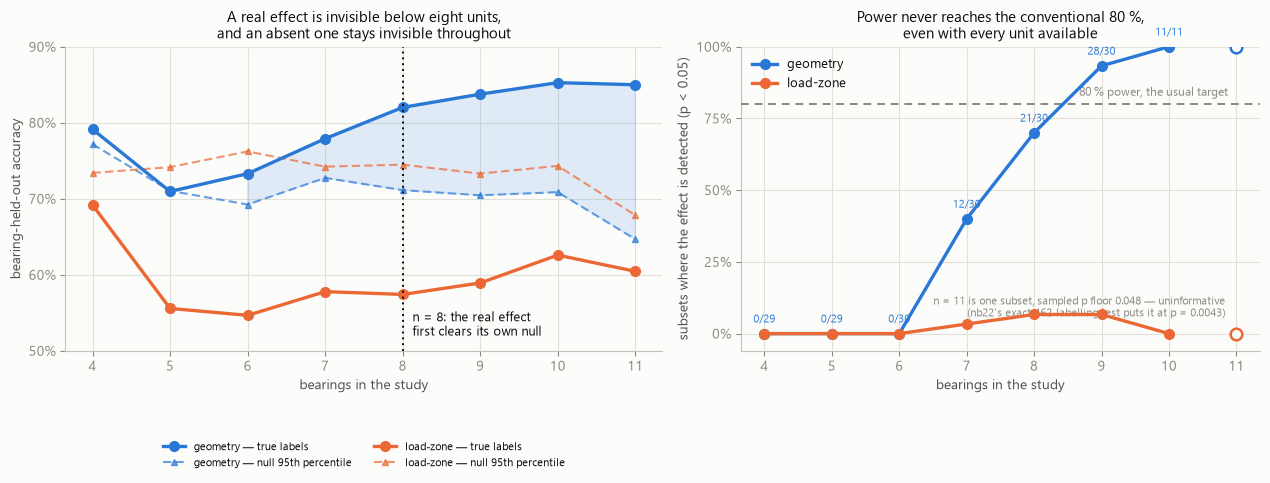


geometry:
  n= 4  true 79.1%  null 95th 77.2%  margin  +2.0%  detected 0/29
  n= 5  true 71.0%  null 95th 71.1%  margin  -0.1%  detected 0/29
  n= 6  true 73.3%  null 95th 69.2%  margin  +4.1%  detected 0/30
  n= 7  true 77.9%  null 95th 72.7%  margin  +5.2%  detected 12/30
  n= 8  true 82.0%  null 95th 71.1%  margin +10.9%  detected 21/30  <- first majority
  n= 9  true 83.8%  null 95th 70.5%  margin +13.3%  detected 28/30
  n=10  true 85.3%  null 95th 70.9%  margin +14.4%  detected 11/11
  n=11  true 85.0%  null 95th 64.7%  margin +20.3%  detected 1/1

load-zone:
  n= 4  true 69.2%  null 95th 73.4%  margin  -4.2%  detected 0/29
  n= 5  true 55.6%  null 95th 74.2%  margin -18.6%  detected 0/29
  n= 6  true 54.7%  null 95th 76.2%  margin -21.6%  detected 0/30
  n= 7  true 57.8%  null 95th 74.2%  margin -16.4%  detected 1/30
  n= 8  true 57.4%  null 95th 74.5%  margin -17.1%  detected 2/30
  n= 9  true 58.9%  null 95th 73.3%  margin -14.4%  detected 2/30
  n=10  true 62.6%  null 95th 7

In [2]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.4),
                               gridspec_kw=dict(width_ratios=[1.15, 1]))
for ch in ("geometry", "load-zone"):
    s = S[S["channel"] == ch]
    axa.plot(s["n"], 100 * s["true"], color=CH[ch], lw=2.4, marker="o", ms=7,
             zorder=4, label=f"{ch} — true labels")
    axa.plot(s["n"], 100 * s["null95"], color=CH[ch], lw=1.5, ls=(0, (4, 2)),
             marker="^", ms=5, alpha=0.7, zorder=3,
             label=f"{ch} — null 95th percentile")
    axa.fill_between(s["n"], 100 * s["null95"], 100 * s["true"],
                     where=s["true"] > s["null95"], color=CH[ch], alpha=0.13, zorder=2)
g = S[S["channel"] == "geometry"]
first = int(g[(g["power"] >= 0.5) & (g["k"] >= 5)]["n"].min())
axa.axvline(first, color=INK, lw=1.4, ls=(0, (1, 2)), zorder=5)
axa.annotate(f"n = {first}: the real effect\nfirst clears its own null",
             (first, 52), xytext=(7, 0), textcoords="offset points",
             fontsize=9, color=INK)
axa.set_xlabel("bearings in the study")
axa.set_ylabel("bearing-held-out accuracy")
axa.set_xticks(sorted(S["n"].unique()))
axa.set_yticks([50, 60, 70, 80, 90], ["50%", "60%", "70%", "80%", "90%"])
axa.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=2)
axa.set_title("A real effect is invisible below eight units,\n"
              "and an absent one stays invisible throughout", fontsize=11)

# n = 11 is a single subset whose sampled-permutation p floor is 1/21 = 0.048,
# so its "power" is uninformative -- notebook 22's exact 462-labelling test puts
# that same point at p = 0.0043. Plotted hollow and excluded from the trend.
SOLID = S[S["k"] >= 5]
THIN = S[S["k"] < 5]
for ch in ("geometry", "load-zone"):
    s = SOLID[SOLID["channel"] == ch]
    axb.plot(s["n"], 100 * s["power"], color=CH[ch], lw=2.4, marker="o", ms=7,
             zorder=4, label=ch)
    u = THIN[THIN["channel"] == ch]
    axb.scatter(u["n"], 100 * u["power"], s=70, facecolors=SURFACE,
                edgecolors=CH[ch], linewidths=1.8, zorder=4)
axb.annotate("n = 11 is one subset, sampled p floor 0.048 — uninformative"
             "\n(nb22's exact 462-labelling test puts it at p = 0.0043)",
             (11, 6), xytext=(-8, 0), textcoords="offset points",
             fontsize=8, color=MUTED, ha="right")
axb.axhline(80, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=3)
axb.annotate("80 % power, the usual target", (S["n"].max(), 80), xytext=(-6, 6),
             textcoords="offset points", fontsize=8.5, color=MUTED, ha="right")
for _, r in SOLID[SOLID["channel"] == "geometry"].iterrows():
    axb.annotate(f"{r['hits']}/{r['k']}", (r["n"], 100 * r["power"]), xytext=(0, 8),
                 textcoords="offset points", fontsize=8, color=C_BLUE, ha="center")
axb.set_xlabel("bearings in the study")
axb.set_ylabel("subsets where the effect is detected (p < 0.05)")
axb.set_xticks(sorted(S["n"].unique()))
axb.set_ylim(-6, 100)
axb.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axb.legend(fontsize=9, loc="upper left")
axb.set_title("Power never reaches the conventional 80 %,\neven with every unit available",
              fontsize=11)
plt.tight_layout()
plt.show()

for ch in ("geometry", "load-zone"):
    s = S[S["channel"] == ch]
    print(f"\n{ch}:")
    for _, r in s.iterrows():
        flag = "  <- first majority" if (ch == "geometry" and r["n"] == first) else ""
        print(f"  n={int(r['n']):2d}  true {r['true']:5.1%}  null 95th {r['null95']:5.1%}  "
              f"margin {r['margin']:+6.1%}  detected {r['hits']}/{r['k']}{flag}")

**A real effect needs seven units before it can even be seen, eight before most studies of that size see it, and nine for conventional power.**

The geometry channel carries an effect notebook 22 confirmed at p = 0.0043 on the
full eleven. Restricted to fewer units that same effect is not detectable, and
the curve now separates two reasons for that. At **n = 4 to 6** the exact
per-subset null is *too small to return a significant p at all*: with at most
C(n,k) − 1 non-true labellings inside the subset, the smallest p available is
0.25, 0.10 and 0.067 — so **0 of 29, 0 of 29 and 0 of 30** subsets detect the
effect for a reason that has nothing to do with the effect. At **n = 7** the floor
drops to 0.029 and detection appears at once: **12 of 30**. At **n = 8** it is
**21 of 30** with the margin over the null at **+10.9 points**, and at **n = 9**
it is **28 of 30**. Nothing about the physics changed between six units and
seven — only whether the test could return an answer.

**The null band narrows as units are added, and that is where the power comes
from.** Its 95th percentile falls from **77 % at n = 4** to **70–71 % at n = 8–10**
while the true accuracy climbs from 79 % to 85 %. Both movements matter: a larger
study both measures the effect better and shrinks what chance can imitate. The
n = 4 point makes the distinction sharply — the true accuracy already exceeds its
null band there, by 2.0 points, and not one subset reaches significance.

**The negative control behaves correctly, which is what makes the positive one
believable.** The load-zone channel — real on XJTU-SY, absent on Paderborn
(notebook 22) — sits *below* its null band at every single unit count, with a
margin between −4 and −22 points and at most **2 of 30** subsets ever reaching
significance. A power floor that also "detected" the absent effect would have
been a broken measurement rather than a result.

**Eleven units is adequate for an effect of this size, and only just.** Detection
is **93 %** at n = 9, **11 of 11** at n = 10 and the single n = 11 subset reaches
p = 0.024, so the conventional 80 % target is met from nine units on. That is a
correction to the earlier version of this notebook, which read the curve off 12
subsets per size with a 0.048 p-floor and concluded the project had never had
adequate power; both of those were artifacts of the sampling rather than
properties of the data. What survives is narrower and still uncomfortable: the
margin is nine units for *this* effect, the datasets provide eleven, and a
channel weaker than geometry would need more than either supplies. Notebook 14's
learning curve asked when accuracy *saturates*, which happens earlier than when
an effect becomes *distinguishable from chance*; those are different questions
and the second is the one a claim rests on.

## What this does and does not license

Four limits belong with the number, because it is the kind of number that will
be quoted out of context.

**It is nine units for an effect of this size.** Geometry on Paderborn reaches
about 85 % against a null centred near 44 %. A weaker channel needs more units,
a stronger one fewer, and nothing here estimates that trade — the curve is one
effect size measured at eight study sizes, not a general sample-size formula.

**The subsets stop being independent as n grows.** There are only 11 ways to
choose 10 units from 11 and one way to choose 11, so the points at the right-hand
end are heavily overlapping draws from the same data. Even where 30 subsets are
drawn, all 11 bearings appear in almost all of them — at n = 9 each bearing is in
up to 28 of the 30 — so the Clopper-Pearson intervals reported beside each rate
are optimistic, and the n = 11 point is a single subset.

**The floor moves with n, and below n = 7 it is above 0.05.** Each subset's null
is now enumerated exactly wherever it has at most 40 non-true labellings, and
sampled at 40 above that, so the p-floor is 1/41 = 0.024 from n = 8 on. At n = 6
and below the whole null is smaller than 20 labellings and the smallest p the
design can return exceeds 0.05: **those subsets could not have detected anything**,
and their zero rates should not be read as evidence of a weak effect.

**The forest is smaller than the protocol's.** Fifteen trees rather than 300,
which reproduces notebook 22 at n = 11 to within two points and keeps the fits
tractable. Both the true and the null side use the same forest, so this affects
precision rather than the comparison.

## What this changes

1. **An attribution claim on this kind of data needs nine units for conventional
   power, and cannot be tested at all below seven.** At n = 4–6 the geometry
   channel's genuinely real effect is detected in **0 of 88** subsets, because the
   exact null inside a subset that small cannot return p < 0.05; at n = 7 it is
   **12 of 30**, at n = 8 **21 of 30** with the margin at **+10.9 points**, and at
   n = 9 **28 of 30 (93 %)**. Notebook 14's "about six real units" measured where
   accuracy saturates, which is a different and easier question.
2. **Eleven units is adequate for this effect, and only just.** The 80 % target is
   met from n = 9, and n = 10 and 11 detect in every subset. This corrects the
   earlier reading of this notebook — 12 subsets per size and a 0.048 p-floor made
   it look as though the project had never had adequate power. The honest statement
   is that the margin is two units for the strongest channel measured here, and
   that a weaker channel would not clear it.
3. **The power comes from the null narrowing, not only from accuracy rising.**
   The null 95th percentile falls from **77 % at n = 4** to **70–71 % at n = 8–10**
   as the true accuracy climbs 79 % → 85 %. Adding units shrinks what chance can
   imitate, which is the half a learning curve cannot show.
4. **The negative control validates the measurement.** The load-zone channel,
   which notebook 22 showed is absent on this rig, sits below its null at every
   unit count (margin −4 to −22 points, at most 2 of 30 subsets significant). The
   curve detects the real effect and not the absent one, which is the property
   that makes the nine-unit figure credible.
5. **The twin now has a quantitative target rather than an architectural
   motivation.** Notebook 16 handed Phase 1 the job of simulating lifetime;
   notebook 22 argued on evidential grounds that units are the binding
   constraint. This says what the twin must deliver to be worth building:
   **enough units to carry a channel weaker than geometry past nine**, since the
   real fleet clears that bar for its strongest channel and nothing more.